In [9]:
import matplotlib.pyplot as plt
import numpy as np

# nbin mitigation

   nchan   mitigation (ratio unmet)   mitigation (ratio met)
     480                      0.000                    0.500
     960                      0.000                    0.500
    1920                      0.000                    0.500
    3840                      0.500                    0.500
    7680                      0.500                    0.500

Saved plot to nbin_mitigation.png


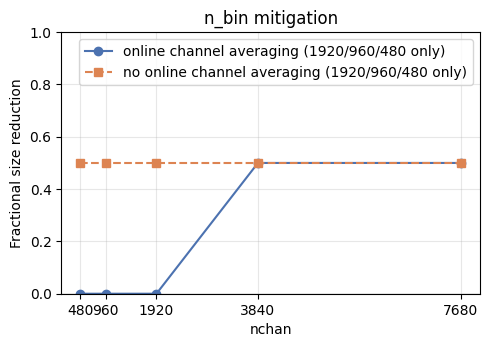

In [20]:
"""
Compute and plot the n_bin mitigation lever as a function of nchan.

Mirrors the eligibility rule already used in checkproductsize.py's
mitigate_sizes():

    (nchan in (7680, 3840))
    or (nchan in (1920, 960, 480) and equal_to_n_digits(ch_width_ratio, 2.667, 4))
    -> nbin = 2

Everything else -> nbin = 1.

Note this is a LOOKUP, not a continuous function of nchan: only a
specific, finite set of channel counts are eligible at all. The plot
therefore shows mitigation at the relevant candidate nchan values
(plus some non-eligible values for contrast), not a smooth curve.

The ratio condition (channel width vs effective bandwidth ~= 2.667,
a fixed spectral-averaging factor used elsewhere in the pipeline) only
matters for the three smaller channel counts (480/960/1920). Since
this script has no measurement set to pull a real ratio from, both the
"ratio not satisfied" (conservative default, matches the eligibility
check literally) and "ratio satisfied" cases are plotted, so the effect
of that condition is visible rather than silently assumed away.
"""


# -- 1. mitigation formula --------------------------------------------------

def nbin_for_nchan(nchan: int, ratio_satisfied: bool = False) -> int:
    """Reproduces the eligibility check from mitigate_sizes()."""
    if nchan in (7680, 3840):
        return 2
    if nchan in (1920, 960, 480) and ratio_satisfied:
        return 2
    return 1


def mitigation_nbin(nbin: int) -> float:
    """Fractional cube-size reduction from channel binning.
    Exact: cubesize scales as 1/nbin, so the reduction is 1 - 1/nbin."""
    return 1.0 - 1.0 / nbin


def mitigation_for_nchan(nchan: int, ratio_satisfied: bool = False) -> float:
    return mitigation_nbin(nbin_for_nchan(nchan, ratio_satisfied))


# -- 2. evaluate over the candidate nchan values -----------------------------

# The five nchan values the eligibility rule actually treats specially.
eligible_nchans = [480, 960, 1920, 3840, 7680]

all_nchans = sorted(eligible_nchans)

mitigation_ratio_false = [mitigation_for_nchan(n, ratio_satisfied=False) for n in all_nchans]
mitigation_ratio_true = [mitigation_for_nchan(n, ratio_satisfied=True) for n in all_nchans]

print(f"{'nchan':>8} {'mitigation (ratio unmet)':>26} {'mitigation (ratio met)':>24}")
for n, m_false, m_true in zip(all_nchans, mitigation_ratio_false, mitigation_ratio_true):
    print(f"{n:>8} {m_false:>26.3f} {m_true:>24.3f}")


# -- 3. plot ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 5/1.4))

ax.plot(all_nchans, mitigation_ratio_false, marker="o", label="online channel averaging (1920/960/480 only)",
        color="#4C72B0")
ax.plot(all_nchans, mitigation_ratio_true, marker="s", linestyle="--",
        label="no online channel averaging (1920/960/480 only)", color="#DD8452")

ax.set_xticks(all_nchans)
ax.set_xlabel("nchan")
ax.set_ylabel("Fractional size reduction")
ax.set_title("n_bin mitigation")
ax.set_ylim(0, 1)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("nbin_mitigation.png", dpi=150)
print("\nSaved plot to nbin_mitigation.png")

# PB mitigation

    PB   mitigation (single pointing)    mitigation (mosaic)
  0.30                          0.000                  0.000
  0.50                          0.000                  0.000
  0.70                          0.000                  0.000
  0.80                          0.234                  0.000
  0.90                          0.395                  0.000
  1.00                          0.510                  0.000

Saved plot to pb_mitigation.png


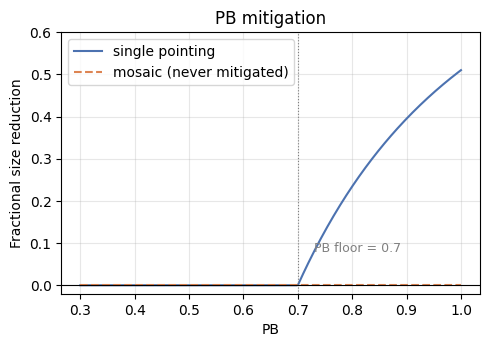

In [21]:
"""
Compute and plot the PB (field-of-view) mitigation lever as a function
of the original primary beam size PB.

Two cases:

  - Mosaics: FoV mitigation is not available at all -> mitigation = 0
    for every PB.
  - Single pointings: PB can be tightened down to a floor of 0.7 (the
    same cap already used in mitigate_sizes()'s hm_imsize logic). If
    the original PB is already at or below that floor there is nothing
    left to mitigate -> mitigation = 0. Above the floor, the cube/image
    area scales with PB^2 (area of the circular FoV), so shrinking the
    diameter from PB down to 0.7 removes a fraction

        mitigation(PB) = 1 - (0.7 / PB)^2        for PB > 0.7
        mitigation(PB) = 0                        for PB <= 0.7

Note: the prompt describing this lever stated the PB<=0.7 and PB>0.7
cases in the opposite order from what the formula itself implies; this
script follows the formula (mitigation is only positive once PB
exceeds the 0.7 floor, since that's the only regime where there's
still room to shrink it) -- worth double-checking against intent
before this is relied on.
"""

PB_FLOOR = 0.7


# -- 1. mitigation formula --------------------------------------------------

def mitigation_pb(pb: float, is_mosaic: bool = False, floor: float = PB_FLOOR) -> float:
    """Fractional cube/image-size reduction from tightening the FoV.
    Derived from the area of the circular FoV (~ PB^2): shrinking the
    diameter from `pb` down to `floor` removes 1 - (floor/pb)^2 of the area."""
    if is_mosaic:
        return 0.0
    if pb <= floor:
        return 0.0
    return 1.0 - (floor / pb) ** 2


# -- 2. evaluate over a range of PB values -----------------------------------

pb_values = np.linspace(0.3, 1.0, 300)
mitigation_single_pointing = [mitigation_pb(pb, is_mosaic=False) for pb in pb_values]
mitigation_mosaic = [mitigation_pb(pb, is_mosaic=True) for pb in pb_values]

sample_pbs = [0.3, 0.5, 0.7, 0.8, 0.9, 1.0]
print(f"{'PB':>6} {'mitigation (single pointing)':>30} {'mitigation (mosaic)':>22}")
for pb in sample_pbs:
    print(f"{pb:>6.2f} {mitigation_pb(pb, is_mosaic=False):>30.3f} "
          f"{mitigation_pb(pb, is_mosaic=True):>22.3f}")


# -- 3. plot ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 5/1.4))

ax.plot(pb_values, mitigation_single_pointing, label="single pointing", color="#4C72B0")
ax.plot(pb_values, mitigation_mosaic, label="mosaic (never mitigated)",
        color="#DD8452", linestyle="--")

ax.axvline(PB_FLOOR, color="gray", linewidth=0.8, linestyle=":")
ax.annotate(f"PB floor = {PB_FLOOR}", xy=(PB_FLOOR, 0.02), xytext=(PB_FLOOR + 0.03, 0.08),
            fontsize=9, color="gray")

ax.set_xlabel("PB")
ax.set_ylabel("Fractional size reduction")
ax.set_title("PB mitigation")
ax.set_ylim(-0.02, 0.6)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("pb_mitigation.png", dpi=150)
print("\nSaved plot to pb_mitigation.png")

# hm_cell mitigation

   ppb    mitigation (robust=2.0)    mitigation (other robust)
  2.50                      0.000                        0.000
  3.00                      0.000                        0.000
  3.25                      0.000                        0.148
  3.50                      0.138                        0.265
  4.00                      0.340                        0.438
  5.00                      0.577                        0.640
  6.00                      0.707                        0.750

Saved plot to cell_mitigation.png


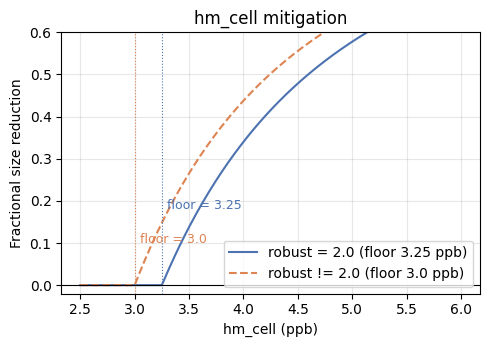

In [29]:
"""
Compute and plot the cell (pixel size, hm_cell) mitigation lever as a
function of the original cell size, expressed in pixels-per-beam (ppb).

Two cases, matching the existing mitigate_sizes() logic:

  - robust = 2.0: hm_cell is tightened down to a floor of 3.25 ppb
    (the special case called out in the code to avoid undersampling
    the beam, PIPE-107).
  - robust != 2.0 (including robust = None): hm_cell is tightened down
    to a floor of 3.0 ppb.

If the original cell size (in ppb) is already at or below the
applicable floor there is nothing left to mitigate -> mitigation = 0.
Above the floor, the image area scales with cell_size^2 (same
area-scaling argument as the PB lever), so shrinking ppb from its
original value down to the floor removes a fraction

    mitigation(ppb) = 1 - (floor / ppb)^2   for ppb > floor
    mitigation(ppb) = 0                      for ppb <= floor

with floor = 3.25 (robust = 2.0) or floor = 3.0 (otherwise).
"""

import matplotlib.pyplot as plt
import numpy as np

CELL_FLOOR_ROBUST_2 = 3.25
CELL_FLOOR_DEFAULT = 3.0


# -- 1. mitigation formula --------------------------------------------------

def mitigation_cell(ppb: float, robust: float | None = None) -> float:
    """Fractional cube/image-size reduction from tightening the cell size.
    Derived from the area scaling of the pixel grid (~ ppb^2): shrinking
    from `ppb` down to the applicable floor removes 1 - (floor/ppb)^2 of
    the area."""
    floor = CELL_FLOOR_ROBUST_2 if robust == 2.0 else CELL_FLOOR_DEFAULT
    if ppb <= floor:
        return 0.0
    return 1.0 - (floor / ppb) ** 2


# -- 2. evaluate over a range of ppb values -----------------------------------

ppb_values = np.linspace(2.5, 6.0, 300)
mitigation_robust2 = [mitigation_cell(ppb, robust=2.0) for ppb in ppb_values]
mitigation_default = [mitigation_cell(ppb, robust=None) for ppb in ppb_values]

sample_ppbs = [2.5, 3.0, 3.25, 3.5, 4.0, 5.0, 6.0]
print(f"{'ppb':>6} {'mitigation (robust=2.0)':>26} {'mitigation (other robust)':>28}")
for ppb in sample_ppbs:
    print(f"{ppb:>6.2f} {mitigation_cell(ppb, robust=2.0):>26.3f} "
          f"{mitigation_cell(ppb, robust=None):>28.3f}")


# -- 3. plot ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 5/1.4))

ax.plot(ppb_values, mitigation_robust2, label="robust = 2.0 (floor 3.25 ppb)", color="#4C72B0")
ax.plot(ppb_values, mitigation_default, label="robust != 2.0 (floor 3.0 ppb)",
        color="#DD8452", linestyle="--")

ax.axvline(CELL_FLOOR_ROBUST_2, color="#4C72B0", linewidth=0.8, linestyle=":")
ax.axvline(CELL_FLOOR_DEFAULT, color="#DD8452", linewidth=0.8, linestyle=":")
ax.annotate(f"floor = {CELL_FLOOR_DEFAULT}", xy=(CELL_FLOOR_DEFAULT, 0.02),
            xytext=(CELL_FLOOR_DEFAULT + 0.05, 0.10), fontsize=9, color="#DD8452")
ax.annotate(f"floor = {CELL_FLOOR_ROBUST_2}", xy=(CELL_FLOOR_ROBUST_2, 0.02),
            xytext=(CELL_FLOOR_ROBUST_2 + 0.05, 0.18), fontsize=9, color="#4C72B0")

ax.set_xlabel("hm_cell (ppb)")
ax.set_ylabel("Fractional size reduction")
ax.set_title("hm_cell mitigation")
ax.set_ylim(-0.02, 0.6)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("hm_cell_mitigation.png", dpi=150)
print("\nSaved plot to cell_mitigation.png")

# ROI mitigation

  ROI fraction   mitigation
          0.00        1.000
          0.20        0.800
          0.40        0.600
          0.50        0.500
          0.60        0.400
          0.80        0.200
          1.00        0.000

Saved plot to roi_mitigation.png


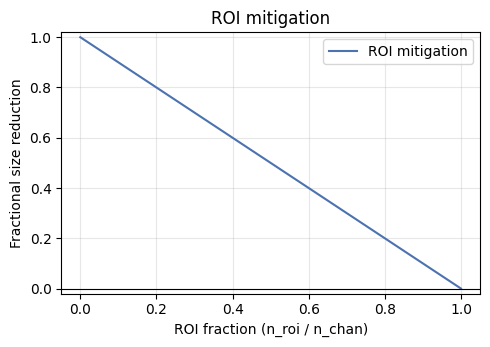

In [31]:
"""
Compute and plot the ROI (region of interest / channel selection)
mitigation lever as a function of the fraction of the spw's channels
kept.

ROI is not yet an implemented mitigation parameter in the pipeline;
it is planned to become available from the context in the future.
Unlike n_bin, PB, and hm_cell, there is no floor/threshold to derive
here and no case split (e.g. mosaic vs single pointing, robust=2.0 vs
not): ROI mitigation simply selects a subset of the total channels of
a spw, so the size reduction is the direct linear complement of the
fraction of channels kept:

    mitigation(n_roi, n_total) = 1 - n_roi / n_total

or, in terms of the ROI fraction f = n_roi / n_total:

    mitigation(f) = 1 - f

This is linear rather than quadratic (as the PB/cell levers are)
because a channel selection is a 1-D cut along the spectral axis, not
a 2-D area cut across the image plane.
"""

import matplotlib.pyplot as plt
import numpy as np


# -- 1. mitigation formula --------------------------------------------------

def mitigation_roi(n_roi: float, n_total: float) -> float:
    """Fractional cube-size reduction from restricting to a region of
    interest. Linear in the fraction of channels kept: cubesize scales
    directly with nchan, so keeping n_roi of n_total channels removes
    1 - n_roi/n_total of the cube."""
    if n_total <= 0:
        raise ValueError("n_total must be positive")
    if n_roi > n_total:
        raise ValueError("n_roi cannot exceed n_total")
    return 1.0 - n_roi / n_total


def mitigation_roi_fraction(f: float) -> float:
    """Same formula, expressed directly in terms of the ROI fraction
    f = n_roi / n_total."""
    return mitigation_roi(f, 1.0)


# -- 2. evaluate over a range of ROI fractions --------------------------------

roi_fractions = np.linspace(0.0, 1.0, 300)
mitigation_values = [mitigation_roi_fraction(f) for f in roi_fractions]

sample_fractions = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
print(f"{'ROI fraction':>14} {'mitigation':>12}")
for f in sample_fractions:
    print(f"{f:>14.2f} {mitigation_roi_fraction(f):>12.3f}")


# -- 3. plot ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 5/1.4))

ax.plot(roi_fractions, mitigation_values, label="ROI mitigation", color="#4C72B0")

ax.set_xlabel("ROI fraction (n_roi / n_chan)")
ax.set_ylabel("Fractional size reduction")
ax.set_title("ROI mitigation")
ax.set_ylim(-0.02, 1.02)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("roi_mitigation.png", dpi=150)
print("\nSaved plot to roi_mitigation.png")